# CrowdVision Phase 5 - CSRNet trên ShanghaiTech Part A

Mục tiêu: huấn luyện CSRNet đúng công thức gốc, đánh giá MAE/RMSE trên tập test chính thức, trực quan hóa density map và lưu kết quả. Notebook dùng module `src/crowd_counting/csrnet.py` có sẵn trong project, nên cùng một model sẽ được dùng lại trong Streamlit ở các phase sau.

Khác với bản notebook trước, bản này sửa các nguyên nhân khiến MAE lên 162:

- Ground truth dùng geometry-adaptive Gaussian (đúng cho Part A) thay cho sigma cố định.
- Có augmentation: random crop nửa ảnh và lật ngang.
- Target 1/8 tính bằng sum-pooling nên tổng density luôn bằng số người.
- Huấn luyện nhiều epoch hơn, có thể chạy tiếp sau khi Colab ngắt kết nối.
- Chọn checkpoint tốt nhất bằng 30 ảnh tách ra từ tập train. Tập test chỉ dùng một lần ở cuối.

In [7]:
import torch
assert torch.cuda.is_available(), 'Chọn Runtime > Change runtime type > GPU.'
torch.cuda.get_device_name(0)

'Tesla T4'

## Mount Drive và import source của project

Project nằm ở `MyDrive/CrowdVision`. Notebook import `src.crowd_counting` từ thư mục này.

In [8]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import sys
PROJECT = Path('/content/drive/MyDrive/CrowdVision')
assert (PROJECT/'src/crowd_counting/csrnet.py').exists(), 'Copy the project folder to MyDrive/CrowdVision first.'
sys.path.insert(0, str(PROJECT))
!pip -q install scipy pillow matplotlib pandas

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Dữ liệu ShanghaiTech

Cell này bỏ qua bước tải và giải nén nếu dữ liệu đã có trong Drive.

In [9]:
import urllib.request, zipfile
DATA_ROOT = PROJECT/'datasets/shanghaitech'
DATA_ROOT.mkdir(parents=True, exist_ok=True)
ARCHIVE = DATA_ROOT/'ShanghaiTech.zip'
URL = 'https://www.dropbox.com/scl/fi/dkj5kulc9zj0rzesslck8/ShanghaiTech_Crowd_Counting_Dataset.zip?rlkey=ymbcj50ac04uvqn8p49j9af5f&dl=1'
if not list(DATA_ROOT.rglob('part_A_final')):
    if not ARCHIVE.exists():
        urllib.request.urlretrieve(URL, ARCHIVE)
    with zipfile.ZipFile(ARCHIVE) as z:
        z.extractall(DATA_ROOT)
found = list(DATA_ROOT.rglob('part_A_final'))
assert found, 'Could not find part_A_final after extraction; inspect archive layout.'
DATASET_ROOT = found[0].parent
DATASET_ROOT

PosixPath('/content/drive/MyDrive/CrowdVision/datasets/shanghaitech')

## Kiến thức cần hiểu trước khi code

**CSRNet không phát hiện từng người.** Mạng nhận một ảnh và trả về density map có kích thước bằng 1/8 ảnh. Mỗi giá trị trong bản đồ là "lượng người" ở vùng đó, và tổng toàn bản đồ là số người ước lượng. Vì vậy mạng không cần bounding box và không bị ảnh hưởng bởi việc người che nhau hay nhỏ vài pixel, miễn là vùng đầu người vẫn còn dấu hiệu texture.

**Ground truth density map.** Dataset chỉ có tọa độ đầu người. Mỗi điểm được thay bằng một Gaussian có tổng bằng 1, cộng tất cả lại thì được bản đồ có tổng đúng bằng số người.

**Geometry-adaptive kernel (Part A).** Người xa camera thì nhỏ và sát nhau, người gần thì to. Sigma của mỗi điểm được đặt bằng 0.3 lần khoảng cách trung bình tới 3 điểm gần nhất, nên vùng đông có Gaussian hẹp, vùng thưa có Gaussian rộng. Part B ít đông hơn nên dùng sigma cố định.

**Kiến trúc.** Frontend là 10 lớp conv đầu của VGG16 (khởi tạo từ ImageNet) cùng 3 max-pool, giảm độ phân giải 8 lần. Backend gồm 6 lớp conv dilation 2 để mở rộng vùng nhìn mà không giảm thêm độ phân giải, cuối cùng là conv 1x1 ra 1 kênh.

**Huấn luyện.** Mỗi lần lấy một crop ngẫu nhiên bằng nửa ảnh (và lật ngang), target là sum-pooling 8x8 của density gốc, loss là tổng bình phương sai số.

In [10]:
import random
import numpy as np
import pandas as pd
import scipy.io as sio
import torch.nn.functional as F
from PIL import Image
from scipy.spatial import KDTree
from torch.utils.data import DataLoader, Dataset

MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)
CACHE = Path('/content/density_cache')
CACHE.mkdir(exist_ok=True)


def split_dirs(part, split):
    base = DATASET_ROOT / f'{part}_final' / f'{split}_data'
    images, gt = base / 'images', base / 'ground_truth'
    if not images.is_dir() or not gt.is_dir():
        raise FileNotFoundError(f'Expected {images} and {gt}')
    return images, gt


def get_points(mat_path):
    data = sio.loadmat(mat_path)
    return data['image_info'][0, 0]['location'][0, 0].astype(np.float32) - 1


def adaptive_density(h, w, points):
    out = np.zeros((h, w), np.float32)
    n = len(points)
    if n == 0:
        return out
    if n > 1:
        dist, _ = KDTree(points).query(points, k=min(4, n))
        sigmas = 0.3 * dist[:, 1:].mean(axis=1)
    else:
        sigmas = np.array([(h + w) / 8.0])
    for (x, y), s in zip(points, sigmas):
        ix, iy = int(round(x)), int(round(y))
        if not (0 <= ix < w and 0 <= iy < h):
            continue
        s = max(float(s), 1.0)
        r = int(3 * s)
        x0, x1 = max(0, ix - r), min(w, ix + r + 1)
        y0, y1 = max(0, iy - r), min(h, iy + r + 1)
        xs = np.arange(x0, x1) - ix
        ys = np.arange(y0, y1) - iy
        g = np.exp(-(xs[None, :] ** 2 + ys[:, None] ** 2) / (2 * s * s))
        out[y0:y1, x0:x1] += g / g.sum()
    return out


def density_map(name, h, w, points):
    cached = CACHE / f'{name}.npy'
    if cached.exists():
        return np.load(cached)
    d = adaptive_density(h, w, points)
    np.save(cached, d)
    return d


class CrowdDataset(Dataset):
    def __init__(self, files, gt_dir, train):
        self.files, self.gt_dir, self.train = files, gt_dir, train

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        p = self.files[i]
        img = Image.open(p).convert('RGB')
        w, h = img.size
        points = get_points(self.gt_dir / f'GT_{p.stem}.mat')
        x = ((np.asarray(img, np.float32) / 255 - MEAN) / STD).transpose(2, 0, 1)
        if not self.train:
            return torch.from_numpy(x.copy()), float(len(points))
        d = density_map(p.stem, h, w, points)
        ch, cw = (h // 2) // 8 * 8, (w // 2) // 8 * 8
        top, left = random.randint(0, h - ch), random.randint(0, w - cw)
        x, d = x[:, top:top + ch, left:left + cw], d[top:top + ch, left:left + cw]
        if random.random() < 0.5:
            x, d = x[:, :, ::-1], d[:, ::-1]
        return torch.from_numpy(x.copy()), torch.from_numpy(d.copy())


train_dir, train_gt = split_dirs('part_A', 'train')
all_files = sorted(train_dir.glob('*.jpg'))
val_files = random.Random(0).sample(all_files, 30)
train_files = [f for f in all_files if f not in set(val_files)]

train_loader = DataLoader(CrowdDataset(train_files, train_gt, True), batch_size=1, shuffle=True, num_workers=2)
val_loader = DataLoader(CrowdDataset(val_files, train_gt, False), batch_size=1, shuffle=False, num_workers=2)

check = train_files[0]
check_points = get_points(train_gt / f'GT_{check.stem}.mat')
check_w, check_h = Image.open(check).size
len(check_points), float(density_map(check.stem, check_h, check_w, check_points).sum())

(1546, 1546.0001220703125)

Kết quả của cell trên cho hai số gần bằng nhau (số điểm annotation và tổng density). Nếu lệch nhiều thì ground truth bị sai, dừng lại kiểm tra trước khi train.

## Huấn luyện

Hyperparameter theo bản gốc: SGD, momentum 0.95, weight decay 5e-4, learning rate rất nhỏ, loss MSE dạng tổng. Mỗi epoch ghi một dòng vào `outputs/csrnet/train_log.csv` (val MAE và RMSE trên 30 ảnh validation). Checkpoint tốt nhất theo val MAE được lưu thành `csrnet_a_best.pth`, trạng thái mới nhất lưu ở `csrnet_a_last.pt` để chạy tiếp.

Nếu Colab ngắt kết nối, chạy lại các cell từ đầu rồi chạy lại cell này, nó sẽ tự tiếp tục từ epoch cuối đã lưu.

Cách theo dõi: val MAE phải giảm dần qua các epoch. Nếu sau khoảng 20 epoch mà val MAE vẫn không xuống dưới vài trăm hoặc loss thành `nan`, hãy dừng và gửi log cho mình thay vì chạy tiếp.

In [11]:
import csv
from torchvision.models import vgg16, VGG16_Weights
from src.crowd_counting import CSRNet

EPOCHS = 0
LR = 1e-6
CKPT_DIR = PROJECT / 'models/csrnet'
OUT = PROJECT / 'outputs/csrnet'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
LAST, BEST, LOG = CKPT_DIR / 'csrnet_a_last.pt', CKPT_DIR / 'csrnet_a_best.pth', OUT / 'train_log.csv'
device = torch.device('cuda')

model = CSRNet().to(device)
model.frontend.load_state_dict(vgg16(weights=VGG16_Weights.IMAGENET1K_V1).features[:23].state_dict(), strict=True)
opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.95, weight_decay=5e-4)

start, best_mae = 0, float('inf')
if LAST.exists():
    state = torch.load(LAST, map_location=device, weights_only=False)
    model.load_state_dict(state['model'])
    opt.load_state_dict(state['opt'])
    start, best_mae = state['epoch'], state['best_mae']
if not LOG.exists():
    LOG.write_text('epoch,train_loss,val_mae,val_rmse\n')


@torch.inference_mode()
def validate():
    model.eval()
    errors = np.array([model(x.to(device)).sum().item() - gt.item() for x, gt in val_loader])
    return float(np.abs(errors).mean()), float(np.sqrt((errors ** 2).mean()))


for epoch in range(start, EPOCHS):
    model.train()
    total = 0.0
    for x, d in train_loader:
        x, d = x.to(device), d.to(device)
        target = F.avg_pool2d(d[:, None], 8) * 64
        opt.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(x), target, reduction='sum')
        loss.backward()
        opt.step()
        total += loss.item()
    val_mae, val_rmse = validate()
    if val_mae < best_mae:
        best_mae = val_mae
        torch.save(model.state_dict(), BEST)
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'epoch': epoch + 1, 'best_mae': best_mae}, LAST)
    with LOG.open('a') as f:
        f.write(f'{epoch + 1},{total / len(train_loader):.4f},{val_mae:.2f},{val_rmse:.2f}\n')
    print(f'epoch {epoch + 1}/{EPOCHS} loss={total / len(train_loader):.2f} val_mae={val_mae:.2f} val_rmse={val_rmse:.2f} best={best_mae:.2f}')

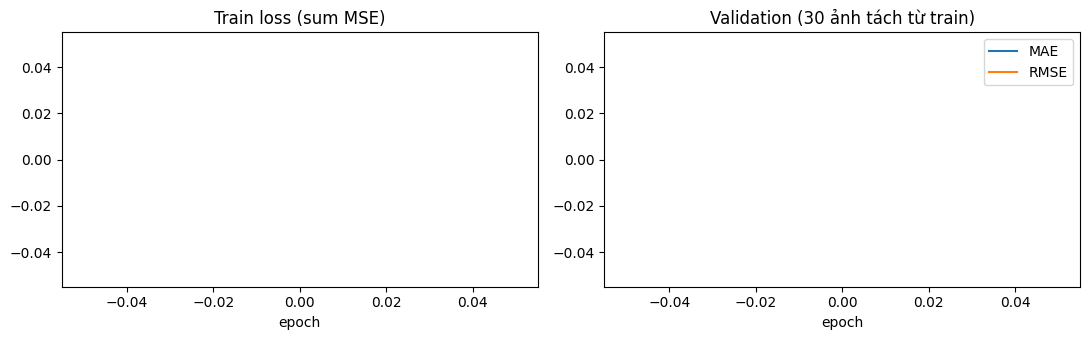

In [12]:
import matplotlib.pyplot as plt
log = pd.read_csv(LOG)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(log.epoch, log.train_loss); ax[0].set_title('Train loss (sum MSE)'); ax[0].set_xlabel('epoch')
ax[1].plot(log.epoch, log.val_mae, label='MAE'); ax[1].plot(log.epoch, log.val_rmse, label='RMSE')
ax[1].set_title('Validation (30 ảnh tách từ train)'); ax[1].set_xlabel('epoch'); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT / 'training_curves.png', dpi=130); plt.show()

## Đánh giá trên tập test chính thức

Cell đầu chọn checkpoint. Mặc định là checkpoint tự huấn luyện ở trên. Nếu bạn có file weights pretrained của người khác (định dạng `.pth` hoặc `.pth.tar`), đặt đường dẫn vào `EXTERNAL`, cell sẽ trích `state_dict` sang file sạch và dùng nó, giúp tránh lỗi khi PyTorch mới chặn load pickle không an toàn. Chỉ làm vậy với file từ nguồn bạn tin cậy.

Việc đánh giá đi qua `CSRNetCounter` trong `src`, đúng đường dẫn sẽ được Streamlit dùng sau này. Ground truth lấy từ số điểm annotation trong file `.mat`, không lấy từ density map. Thời gian đo là thời gian mỗi ảnh gồm đọc ảnh, tiền xử lý và suy luận.

In [13]:
EXTERNAL = PROJECT / 'models/csrnet/PartAmodel_best.pth.tar'
CHECKPOINT = BEST
if EXTERNAL is not None:
    raw = torch.load(EXTERNAL, map_location='cpu', weights_only=False)
    raw = raw.get('state_dict', raw)
    CHECKPOINT = CKPT_DIR / 'csrnet_a_external.pth'
    torch.save({k.removeprefix('module.'): v for k, v in raw.items()}, CHECKPOINT)
CHECKPOINT.name

'csrnet_a_external.pth'

In [15]:
import json, time
from src.crowd_counting import CSRNetCounter

counter = CSRNetCounter(CHECKPOINT, device='cuda')
test_dir, test_gt = split_dirs('part_A', 'test')
test_files = sorted(test_dir.glob('*.jpg'))
counter.predict(test_files[0])

rows = []
for p in test_files:
    t0 = time.perf_counter()
    count = counter.predict(p).count
    ms = (time.perf_counter() - t0) * 1000
    rows.append((p.name, float(len(get_points(test_gt / f'GT_{p.stem}.mat'))), count, ms))

df = pd.DataFrame(rows, columns=['image', 'truth', 'pred', 'ms'])
df['err'] = df.pred - df.truth
df['abs_err'] = df.err.abs()
metrics = {
    'split': 'ShanghaiTech Part A test',
    'images': len(df),
    'MAE': float(df.abs_err.mean()),
    'RMSE': float(np.sqrt((df.err ** 2).mean())),
    'mean_ms_per_image': float(df.ms.mean()),
    'checkpoint': CHECKPOINT.name,
    'gpu': torch.cuda.get_device_name(0),
}
df.to_csv(OUT / 'predictions.csv', index=False)
(OUT / 'metrics.json').write_text(json.dumps(metrics, indent=2))
metrics

{'split': 'ShanghaiTech Part A test',
 'images': 182,
 'MAE': 66.94206327920432,
 'RMSE': 107.15068981210908,
 'mean_ms_per_image': 191.38348396703665,
 'checkpoint': 'csrnet_a_external.pth',
 'gpu': 'Tesla T4'}

In [16]:
bins = [0, 200, 500, 1000, np.inf]
level = pd.cut(df.truth, bins, right=False, labels=['<200', '200-500', '500-1000', '>=1000'])
grouped = df.groupby(level, observed=True)
table = pd.DataFrame({
    'images': grouped.size(),
    'mean_truth': grouped.truth.mean(),
    'MAE': grouped.abs_err.mean(),
    'RMSE': grouped.err.apply(lambda e: np.sqrt((e ** 2).mean())),
    'bias': grouped.err.mean(),
})
table['relative_MAE_%'] = 100 * table.MAE / table.mean_truth
table.round(1).to_csv(OUT / 'error_by_density.csv')
table.round(1)

,images,mean_truth,MAE,RMSE,bias,relative_MAE_%
truth,,,,,,
<200,43,144.7,27.1,36.6,3.5,18.7
200-500,93,323.7,50.6,67.7,-1.8,15.6
500-1000,27,678.6,91.6,120.6,-29.1,13.5
>=1000,19,1280.5,202.0,252.7,-146.1,15.8


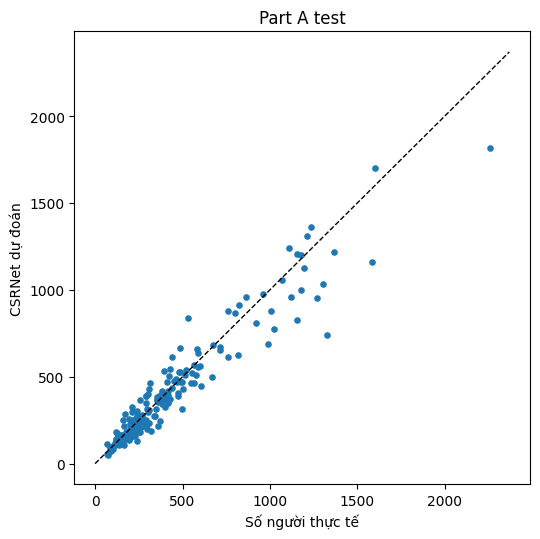

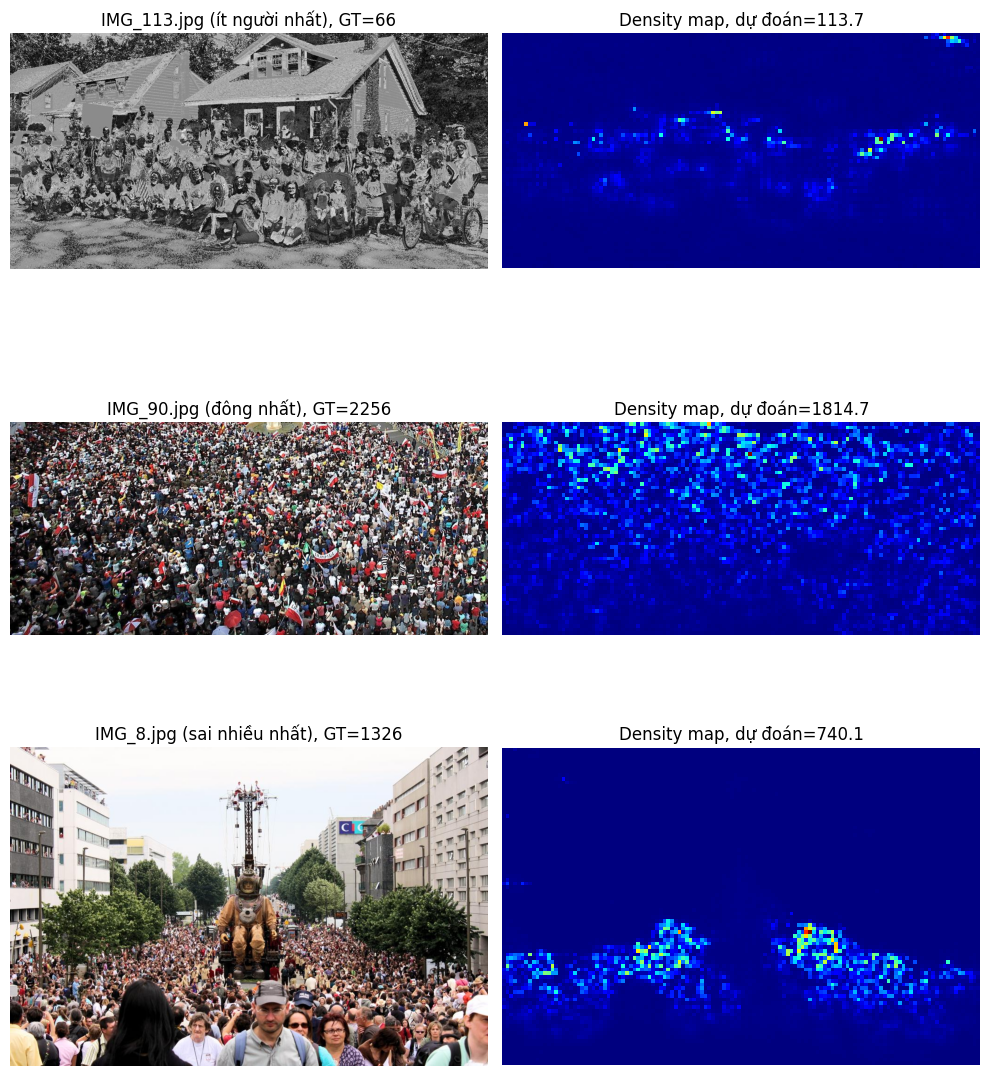

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(df.truth, df.pred, s=14)
lim = max(df.truth.max(), df.pred.max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', linewidth=1)
ax.set_xlabel('Số người thực tế'); ax.set_ylabel('CSRNet dự đoán'); ax.set_title('Part A test')
fig.tight_layout(); fig.savefig(OUT / 'gt_vs_pred.png', dpi=130); plt.show()

picks = {
    'ít người nhất': df.loc[df.truth.idxmin(), 'image'],
    'đông nhất': df.loc[df.truth.idxmax(), 'image'],
    'sai nhiều nhất': df.loc[df.abs_err.idxmax(), 'image'],
}
fig, axes = plt.subplots(len(picks), 2, figsize=(10, 4 * len(picks)))
for row, (label, name) in zip(axes, picks.items()):
    result = counter.predict(test_dir / name)
    truth = df.loc[df.image == name, 'truth'].item()
    row[0].imshow(result.image_rgb); row[0].set_title(f'{name} ({label}), GT={truth:.0f}')
    row[1].imshow(result.density_map, cmap='jet'); row[1].set_title(f'Density map, dự đoán={result.count:.1f}')
    for a in row:
        a.axis('off')
fig.tight_layout(); fig.savefig(OUT / 'density_examples.png', dpi=130); plt.show()

Tham chiếu: bài báo CSRNet báo cáo MAE 68.2 và RMSE 115.0 trên Part A. Các bản tái hiện thường nằm quanh 66 đến 75 cho MAE. Đây chỉ là mốc để biết pipeline có đúng không, không phải cam kết cho lần chạy của bạn.

## Phân tích sai số theo mức độ đông đúc

Part A có ảnh từ vài chục đến hơn ba nghìn người, nên một con số MAE chung che mất hành vi của model. Bảng dưới tách theo số người thực tế. `bias` là sai số có dấu (dương nghĩa là đếm dư, âm là đếm thiếu).